In [106]:
import pandas
import numpy
import matplotlib.pyplot as plt
import seaborn

In [107]:
df = pandas.read_csv("GTEx_Analysis_2025-08-22_v11_RNASeQCv2.4.3_gene_median_tpm.gct.gz", sep="\t", header=2, index_col="Description")

In [108]:
df.shape

(74628, 69)

In [109]:
df.head()

,Name,Adipose_Subcutaneous,Adipose_Visceral_Omentum,Adrenal_Gland,Artery_Aorta,Artery_Coronary,Artery_Tibial,Bladder,Brain_Amygdala,Brain_Anterior_cingulate_cortex_BA24,...,Spleen,Stomach,Stomach_Mixed_Cell,Stomach_Mucosa,Stomach_Muscularis,Testis,Thyroid,Uterus,Vagina,Whole_Blood
Description,,,,,,,,,,,,,,,,,,,,,
DDX11L16,ENSG00000290825.2,0.00000,0.0000,0.00000,0.0000,0.00000,0.00000,0.00000,0.011780,0.000000,...,0.00000,0.00000,0.014928,0.012652,0.015991,0.073208,0.00000,0.00000,0.00000,0.0000
DDX11L1,ENSG00000223972.6,0.00000,0.0000,0.00000,0.0000,0.00000,0.00000,0.00000,0.000000,0.000000,...,0.00000,0.00000,0.000000,0.000000,0.000000,0.000000,0.00000,0.00000,0.00000,0.0000
WASH7P,ENSG00000310526.1,2.45431,1.9053,1.75253,2.3178,2.21944,1.66539,3.14825,0.565228,0.652863,...,5.04503,2.04517,1.868420,1.507490,1.909350,3.126710,4.01324,4.92657,3.85789,2.2098
MIR1302-2HG,ENSG00000243485.6,0.00000,0.0000,0.00000,0.0000,0.00000,0.00000,0.00000,0.000000,0.000000,...,0.00000,0.00000,0.000000,0.000000,0.000000,0.036257,0.00000,0.00000,0.00000,0.0000
FAM138A,ENSG00000237613.3,0.00000,0.0000,0.00000,0.0000,0.00000,0.00000,0.00000,0.012860,0.013432,...,0.00000,0.00000,0.015325,0.013091,0.018168,0.000000,0.00000,0.00000,0.00000,0.0000


In [110]:
df = df.drop("Name", axis=1)

In [111]:
df.shape
df.head()

,Adipose_Subcutaneous,Adipose_Visceral_Omentum,Adrenal_Gland,Artery_Aorta,Artery_Coronary,Artery_Tibial,Bladder,Brain_Amygdala,Brain_Anterior_cingulate_cortex_BA24,Brain_Caudate_basal_ganglia,...,Spleen,Stomach,Stomach_Mixed_Cell,Stomach_Mucosa,Stomach_Muscularis,Testis,Thyroid,Uterus,Vagina,Whole_Blood
Description,,,,,,,,,,,,,,,,,,,,,
DDX11L16,0.00000,0.0000,0.00000,0.0000,0.00000,0.00000,0.00000,0.011780,0.000000,0.010609,...,0.00000,0.00000,0.014928,0.012652,0.015991,0.073208,0.00000,0.00000,0.00000,0.0000
DDX11L1,0.00000,0.0000,0.00000,0.0000,0.00000,0.00000,0.00000,0.000000,0.000000,0.000000,...,0.00000,0.00000,0.000000,0.000000,0.000000,0.000000,0.00000,0.00000,0.00000,0.0000
WASH7P,2.45431,1.9053,1.75253,2.3178,2.21944,1.66539,3.14825,0.565228,0.652863,0.682993,...,5.04503,2.04517,1.868420,1.507490,1.909350,3.126710,4.01324,4.92657,3.85789,2.2098
MIR1302-2HG,0.00000,0.0000,0.00000,0.0000,0.00000,0.00000,0.00000,0.000000,0.000000,0.000000,...,0.00000,0.00000,0.000000,0.000000,0.000000,0.036257,0.00000,0.00000,0.00000,0.0000
FAM138A,0.00000,0.0000,0.00000,0.0000,0.00000,0.00000,0.00000,0.012860,0.013432,0.012474,...,0.00000,0.00000,0.015325,0.013091,0.018168,0.000000,0.00000,0.00000,0.00000,0.0000


In [112]:
(df == 0).mean()

Adipose_Subcutaneous        0.544769
Adipose_Visceral_Omentum    0.546805
Adrenal_Gland               0.560312
Artery_Aorta                0.560996
Artery_Coronary             0.551750
                              ...   
Testis                      0.283325
Thyroid                     0.521051
Uterus                      0.538766
Vagina                      0.533540
Whole_Blood                 0.633301
Length: 68, dtype: float64

/Users/mhuo/miniforge3/envs/srpp_env/lib/python3.14/site-packages/pandas/core/internals/blocks.py:347: RuntimeWarning: divide by zero encountered in log10
  result = func(self.values, **kwargs)


<Axes: ylabel='Count'>

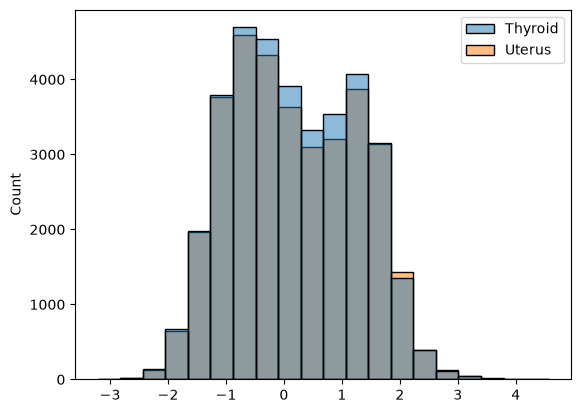

In [113]:
df = numpy.log10(df)
seaborn.histplot([df["Thyroid"], df["Uterus"]], bins=20)

<Axes: xlabel='NOVA2', ylabel='TP53'>

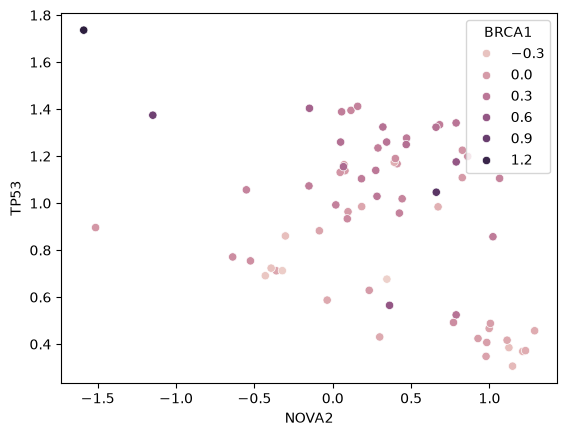

In [114]:
seaborn.scatterplot(x=df.loc["NOVA2"], y=df.loc["TP53"], hue=df.loc["BRCA1"])

In [117]:
10 ** df.loc["BRCA1"]["Breast_Mammary_Tissue"]

np.float64(1.18184)

In [123]:
ann = pandas.read_csv("gencode.v47.annotation.chr22.gtf", sep="\t", header=None)

In [124]:
ann.head()

,0,1,2,3,4,5,6,7,8
0,chr22,HAVANA,gene,10524345,10529164,.,-,.,"gene_id ""ENSG00000294541.1""; gene_type ""lncRNA..."
1,chr22,HAVANA,transcript,10524345,10529164,.,-,.,"gene_id ""ENSG00000294541.1""; transcript_id ""EN..."
2,chr22,HAVANA,exon,10529036,10529164,.,-,.,"gene_id ""ENSG00000294541.1""; transcript_id ""EN..."
3,chr22,HAVANA,exon,10527853,10528040,.,-,.,"gene_id ""ENSG00000294541.1""; transcript_id ""EN..."
4,chr22,HAVANA,exon,10524345,10524446,.,-,.,"gene_id ""ENSG00000294541.1""; transcript_id ""EN..."


In [125]:
ann.rename(columns={0: "Chromosome", 1: "Source", 2: "Feature", 3: "Start", 4: "End", 5: "idk", 6: "Strand", 7: "idk2", 8: "Description"})

,Chromosome,Source,Feature,Start,End,idk,Strand,idk2,Description
0,chr22,HAVANA,gene,10524345,10529164,.,-,.,"gene_id ""ENSG00000294541.1""; gene_type ""lncRNA..."
1,chr22,HAVANA,transcript,10524345,10529164,.,-,.,"gene_id ""ENSG00000294541.1""; transcript_id ""EN..."
2,chr22,HAVANA,exon,10529036,10529164,.,-,.,"gene_id ""ENSG00000294541.1""; transcript_id ""EN..."
3,chr22,HAVANA,exon,10527853,10528040,.,-,.,"gene_id ""ENSG00000294541.1""; transcript_id ""EN..."
4,chr22,HAVANA,exon,10524345,10524446,.,-,.,"gene_id ""ENSG00000294541.1""; transcript_id ""EN..."
...,...,...,...,...,...,...,...,...,...
86154,chr22,HAVANA,exon,50798788,50798991,.,-,.,"gene_id ""ENSG00000307555.1""; transcript_id ""EN..."
86155,chr22,HAVANA,exon,50797082,50797504,.,-,.,"gene_id ""ENSG00000307555.1""; transcript_id ""EN..."
86156,chr22,HAVANA,gene,50798655,50799123,.,+,.,"gene_id ""ENSG00000184319.19""; gene_type ""trans..."
86157,chr22,HAVANA,transcript,50798655,50799123,.,+,.,"gene_id ""ENSG00000184319.19""; transcript_id ""E..."
